# 12_feature_analysis.ipynb — อะไรสัมพันธ์กับการ readmit? (ขั้นที่ 2 จาก 4)

ตอบคำถามของอาจารย์ 2 ข้อ:
1. **เข้าใจโรค**: ปัจจัยไหนสัมพันธ์กับการกลับมา admit ซ้ำ มีทิศทางและขนาดเท่าไร
2. **ช่วยให้ผลดีขึ้นไหม**: เอาความสัมพันธ์ที่เจอมาสร้าง feature แล้วทดสอบแบบ controlled

วิเคราะห์ 4 ชั้น จากง่ายไปซับซ้อน แล้วดูว่าผลสอดคล้องกันไหม (ถ้าทุกวิธีชี้ตรงกัน = ข้อค้นพบแข็งแรง)

| ชั้น | วิธี | ตอบคำถาม |
|---|---|---|
| A | อัตรา readmit รายกลุ่ม, Cramér's V, Mutual information | ตัวแปรเดียวสัมพันธ์แค่ไหน |
| B | Logistic regression → **odds ratio + 95% CI (cluster bootstrap ตามผู้ป่วย)** | ผลของแต่ละปัจจัยเมื่อคุมตัวอื่นแล้ว |
| C | SHAP (XGBoost) + interaction, permutation importance ของ stacking ตัวจริง | โมเดลใช้อะไร รูปทรงความสัมพันธ์ และคู่ตัวแปรที่ส่งผลร่วมกัน |
| D | ทดสอบ feature ใหม่ด้วย GroupKFold บน train | ความรู้ที่ได้ช่วยเพิ่มผลจริงไหม |

**กติกาสำคัญ**: วิเคราะห์และเลือก feature บน **train split เท่านั้น** (ใช้ val ในบางจุดที่ระบุ) ไม่แตะ test เลย เพื่อให้ผลของโมเดลใน notebook ถัดไปยังเชื่อถือได้

**ข้อควรระวังในการเขียนเปเปอร์**: ทุกอย่างในนี้เป็น *association* ไม่ใช่ *causation*

ต้องการ: `readmission_features.py` (โฟลเดอร์เดียวกัน), `split_assignment.csv` และ `model_11_any.pkl` จาก notebook 11, `pip install xgboost` (SHAP คำนวณด้วย xgboost โดยตรง ไม่ต้องลง shap)

## 0. Config + Imports

In [1]:
LABEL_MODE = "any"
RANDOM_STATE = 42
RAW_PATH = "../data/diabetic_data.csv"
SPLIT_PATH = "../outputs/split_assignment.csv"
MODEL_PATH = f"../models/model_11_{LABEL_MODE}.pkl"
OUT_DIR = f"../outputs/12_features_{LABEL_MODE}"

N_BOOT = 200          # จำนวนรอบ bootstrap ของ odds ratio (ลดเป็น 50 ถ้าอยากเร็ว)
SHAP_SAMPLE = 3000    # จำนวนแถวที่ใช้คำนวณ SHAP
INTER_SAMPLE = 1000   # จำนวนแถวที่ใช้คำนวณ SHAP interaction (ช้ากว่า SHAP ปกติมาก)

In [ ]:
import os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import chi2_contingency

from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

from readmission_features import (load_prepared, attach_split, group_discharge,
                                  group_admission_type, group_admission_source)
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False
    print("⚠️ ไม่พบ xgboost — ส่วน SHAP (ชั้น C) จะรันไม่ได้ และชั้น D จะใช้ HistGradientBoosting แทน")

os.makedirs(OUT_DIR, exist_ok=True)

## 1. โหลดข้อมูล + ใช้ split เดียวกับ notebook 11

In [3]:
X, y, groups, meta, readable = load_prepared(RAW_PATH, LABEL_MODE)
split = attach_split(meta, SPLIT_PATH)
tr, va = split == "train", split == "val"

X_tr, y_tr, g_tr = X[tr].reset_index(drop=True), y[tr].reset_index(drop=True), groups[tr]
X_va, y_va = X[va].reset_index(drop=True), y[va].reset_index(drop=True)
R_tr = readable[tr].reset_index(drop=True)   # ข้อมูลแบบอ่านรู้เรื่อง (ยังไม่ encode)

print(f"train n={len(X_tr):,}  base rate={y_tr.mean():.4f}")
print(f"val   n={len(X_va):,}  base rate={y_va.mean():.4f}")
print("(ไม่ได้โหลด test มาใช้ใน notebook นี้)")

train n=63,605  base rate=0.4725
val   n=15,962  base rate=0.4740
(ไม่ได้โหลด test มาใช้ใน notebook นี้)


## ชั้น A — ความสัมพันธ์รายตัวแปร

### A1. อัตรา readmit ตามระดับของตัวแปรสำคัญ
ตัวแปรจำนวนครั้ง (counts) ตัดที่ 5+ เพื่อไม่ให้กลุ่มเล็กๆ ทำให้กราฟแกว่ง เส้นประ = base rate

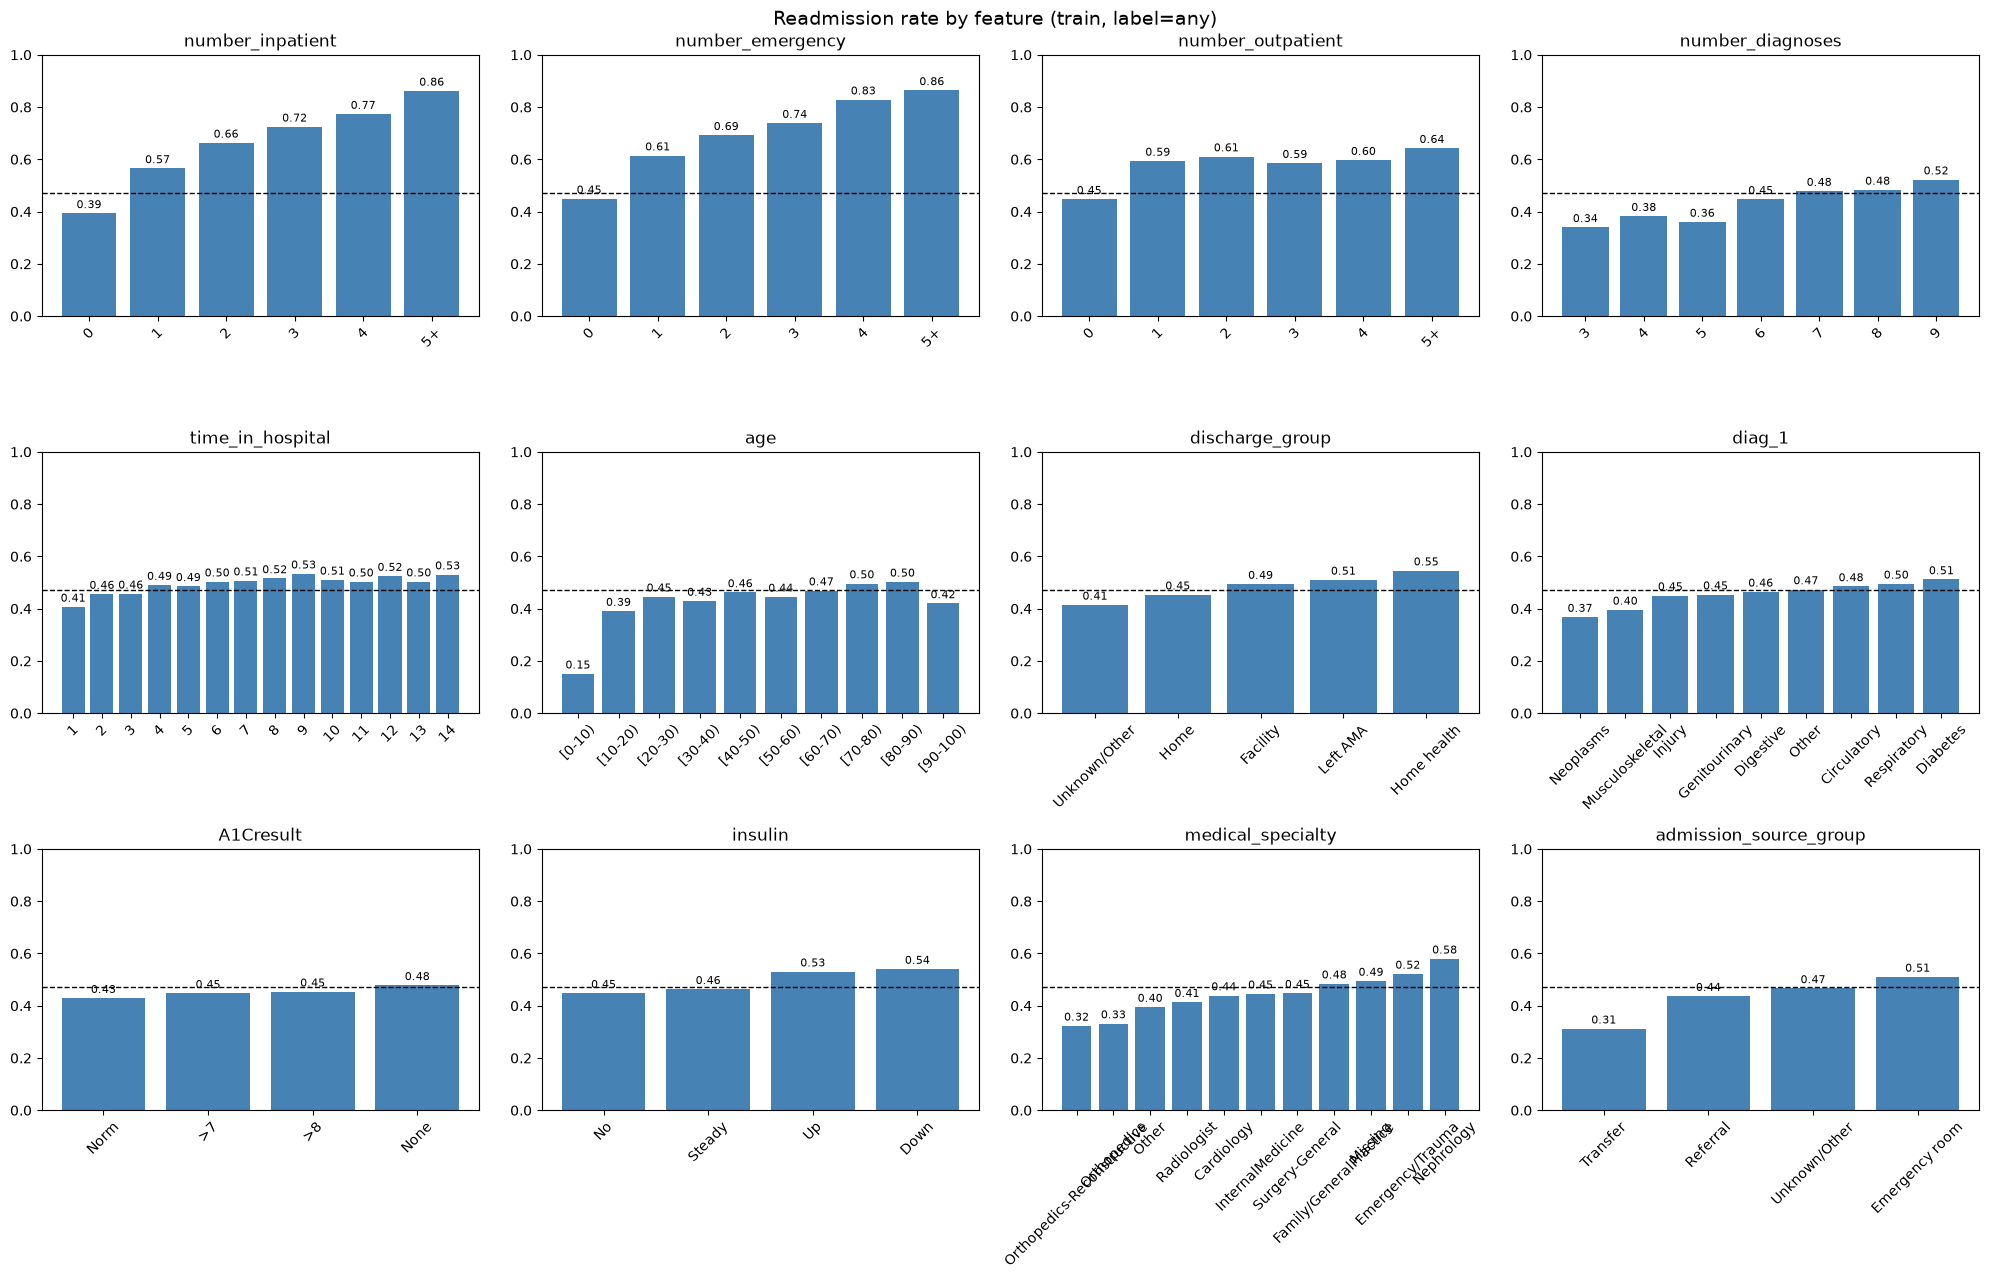

In [4]:
R_tr["discharge_group"] = R_tr["discharge_disposition_id"].apply(group_discharge)
R_tr["admission_type_group"] = R_tr["admission_type_id"].apply(group_admission_type)
R_tr["admission_source_group"] = R_tr["admission_source_id"].apply(group_admission_source)

plot_vars = {
    "number_inpatient": "clip", "number_emergency": "clip", "number_outpatient": "clip",
    "number_diagnoses": "clip9", "time_in_hospital": "raw", "age": "raw",
    "discharge_group": "raw", "diag_1": "raw", "A1Cresult": "raw",
    "insulin": "raw", "medical_specialty": "raw", "admission_source_group": "raw",
}
base = y_tr.mean()
fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for ax, (v, mode) in zip(axes.ravel(), plot_vars.items()):
    s = R_tr[v]
    if mode == "clip":
        s = s.clip(upper=5).astype(int).astype(str).replace("5", "5+")
    elif mode == "clip9":
        s = s.clip(lower=3, upper=9).astype(int).astype(str)
    t = pd.DataFrame({"x": s, "y": y_tr}).groupby("x")["y"].agg(["mean", "size"])
    t = t[t["size"] >= 50]
    if mode == "raw" and v not in ("age", "time_in_hospital"):
        t = t.sort_values("mean")
    ax.bar(t.index.astype(str), t["mean"], color="steelblue")
    ax.axhline(base, ls="--", c="k", lw=1)
    ax.set_title(v); ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=45)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m + 0.02, f"{m:.2f}", ha="center", fontsize=8)
plt.suptitle(f"Readmission rate by feature (train, label={LABEL_MODE})", fontsize=14)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/A1_rates_by_feature.png", dpi=150); plt.show()

### A2. Cramér's V (categorical) + Mutual Information (ทุกตัว)
- **Cramér's V** อยู่ระหว่าง 0–1 วัดความแรงของความสัมพันธ์ระหว่างตัวแปร categorical กับ label
- **Mutual information** จับความสัมพันธ์แบบไม่เป็นเส้นตรงได้ด้วย ใช้จัดอันดับรวมทุก feature

In [5]:
def cramers_v(x, y_):
    ct = pd.crosstab(x, y_)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

cat_vars = [c for c in R_tr.columns if pd.api.types.is_string_dtype(R_tr[c]) and c not in ("readmitted",)]
cramer = (pd.Series({c: cramers_v(R_tr[c], y_tr) for c in cat_vars})
          .sort_values(ascending=False).round(4))
print("Cramér's V (categorical):\n", cramer.head(15).to_string())

discrete_mask = [X_tr[c].nunique() <= 30 for c in X_tr.columns]
mi = pd.Series(mutual_info_classif(X_tr, y_tr, discrete_features=discrete_mask,
                                   random_state=RANDOM_STATE), index=X_tr.columns)
mi = mi.sort_values(ascending=False)
print("\nMutual information (top 15):\n", mi.head(15).round(4).to_string())

Cramér's V (categorical):
 admission_source_group    0.1061
medical_specialty         0.0864
insulin                   0.0700
discharge_group           0.0692
diag_3                    0.0621
diag_1                    0.0620
admission_type_group      0.0584
diabetesMed               0.0575
age                       0.0570
race                      0.0564
diag_2                    0.0499
change                    0.0410
metformin                 0.0329
max_glu_serum             0.0307
A1Cresult                 0.0263

Mutual information (top 15):
 total_prior_visits           0.0355
number_inpatient             0.0318
hospital_stay_x_inpatient    0.0308
visit_number                 0.0307
had_prior_inpatient          0.0254
prior_change_count           0.0159
number_emergency             0.0104
number_diagnoses             0.0080
admission_source_id          0.0064
age_x_medications            0.0061
number_outpatient            0.0054
medical_specialty            0.0038
num_medications

## ชั้น B — Logistic Regression: Odds Ratio เมื่อคุมตัวแปรอื่น

ใช้ตัวแปรที่ตีความได้ทางคลินิก ในหน่วยที่แพทย์คุ้นเคย (ไม่ใช้ feature ที่เป็นผลคูณ เพราะทำให้ตีความ OR ไม่ได้)
- ตัวแปรจำนวนครั้ง: **ต่อ 1 ครั้ง** (ตัดที่ 5)
- อายุ: **ต่อ 10 ปี**, วันนอน: **ต่อ 1 วัน**, จำนวนยา: **ต่อ 5 ชนิด**, lab: **ต่อ 10 รายการ**
- Categorical: one-hot เทียบกับกลุ่มอ้างอิง (reference) ที่ระบุในตาราง

**ทำไมต้อง cluster bootstrap**: ผู้ป่วยคนเดียวมีหลาย encounter ข้อมูลจึงไม่อิสระต่อกัน CI แบบปกติจะแคบเกินจริง จึง resample เป็น "รายผู้ป่วย" แทน

In [6]:
REFS = {
    "gender": "Female", "race": "Caucasian", "admission_type_group": "Emergency",
    "admission_source_group": "Emergency room", "discharge_group": "Home",
    "diag_1": "Circulatory", "A1Cresult": "None", "max_glu_serum": "None",
    "insulin": "No", "metformin": "No", "change": "No", "diabetesMed": "No",
}

def build_lr_design(R):
    D = pd.DataFrame(index=R.index)
    D["age (per 10 y)"] = R["age_ord"] / 10
    D["time_in_hospital (per day)"] = R["time_in_hospital"]
    D["num_lab_procedures (per 10)"] = R["num_lab_procedures"] / 10
    D["num_procedures (per 1)"] = R["num_procedures"]
    D["num_medications (per 5)"] = R["num_medications"] / 5
    D["number_diagnoses (per 1)"] = R["number_diagnoses"]
    for c in ["number_inpatient", "number_emergency", "number_outpatient"]:
        D[f"{c} (per visit, cap 5)"] = R[c].clip(upper=5)
    for c, ref in REFS.items():
        dummies = pd.get_dummies(R[c], prefix=c, prefix_sep=" = ").astype(float)
        dummies = dummies.drop(columns=[f"{c} = {ref}"])
        dummies = dummies.loc[:, dummies.sum() >= 100]   # ตัดกลุ่มเล็กมาก (CI กว้างจนไม่มีความหมาย)
        D = pd.concat([D, dummies], axis=1)
    return D

R_va = readable[va].reset_index(drop=True)
for R in (R_va,):
    R["discharge_group"] = R["discharge_disposition_id"].apply(group_discharge)
    R["admission_type_group"] = R["admission_type_id"].apply(group_admission_type)
    R["admission_source_group"] = R["admission_source_id"].apply(group_admission_source)

D_tr = build_lr_design(R_tr)
D_va = build_lr_design(R_va).reindex(columns=D_tr.columns, fill_value=0)
print(f"Design matrix: {D_tr.shape[1]} ตัวแปร")

def fit_lr(Xd, yd):
    return LogisticRegression(penalty=None, max_iter=5000).fit(Xd, yd)

lr_full = fit_lr(D_tr, y_tr)
print(f"Logistic regression (interpretable) — val ROC-AUC: {roc_auc_score(y_va, lr_full.predict_proba(D_va)[:, 1]):.4f}"
      f"  | val PR-AUC: {average_precision_score(y_va, lr_full.predict_proba(D_va)[:, 1]):.4f}")

Design matrix: 47 ตัวแปร
Logistic regression (interpretable) — val ROC-AUC: 0.6742  | val PR-AUC: 0.6447


In [7]:
# Cluster bootstrap ตามผู้ป่วย
rng = np.random.default_rng(RANDOM_STATE)
uniq = np.unique(g_tr)
rows_by_patient = pd.Series(np.arange(len(g_tr))).groupby(g_tr).apply(np.array)

boot_coefs = []
for b in range(N_BOOT):
    pick = rng.choice(uniq, size=len(uniq), replace=True)
    idx = np.concatenate(rows_by_patient.loc[pick].values)
    boot_coefs.append(fit_lr(D_tr.iloc[idx], y_tr.iloc[idx]).coef_[0])
    if (b + 1) % 50 == 0:
        print(f"  bootstrap {b+1}/{N_BOOT}")
boot_coefs = np.array(boot_coefs)

or_table = pd.DataFrame({
    "OR": np.exp(lr_full.coef_[0]),
    "CI_low": np.exp(np.percentile(boot_coefs, 2.5, axis=0)),
    "CI_high": np.exp(np.percentile(boot_coefs, 97.5, axis=0)),
}, index=D_tr.columns)
or_table["significant"] = (or_table["CI_low"] > 1) | (or_table["CI_high"] < 1)
or_table = or_table.round(3).sort_values("OR", ascending=False)
or_table.to_csv(f"{OUT_DIR}/B_odds_ratios.csv")

print("กลุ่มอ้างอิง:", REFS)
print(or_table.to_string())

  bootstrap 50/200
  bootstrap 100/200
  bootstrap 150/200
  bootstrap 200/200
กลุ่มอ้างอิง: {'gender': 'Female', 'race': 'Caucasian', 'admission_type_group': 'Emergency', 'admission_source_group': 'Emergency room', 'discharge_group': 'Home', 'diag_1': 'Circulatory', 'A1Cresult': 'None', 'max_glu_serum': 'None', 'insulin': 'No', 'metformin': 'No', 'change': 'No', 'diabetesMed': 'No'}
                                           OR  CI_low  CI_high  significant
number_inpatient (per visit, cap 5)     1.514   1.487    1.545         True
admission_type_group = Unknown/Other    1.449   1.330    1.572         True
diabetesMed = Yes                       1.369   1.295    1.433         True
number_emergency (per visit, cap 5)     1.292   1.257    1.332         True
max_glu_serum = >300                    1.256   1.053    1.500         True
discharge_group = Home health           1.159   1.103    1.235         True
admission_type_group = Urgent           1.152   1.082    1.213         True
numbe

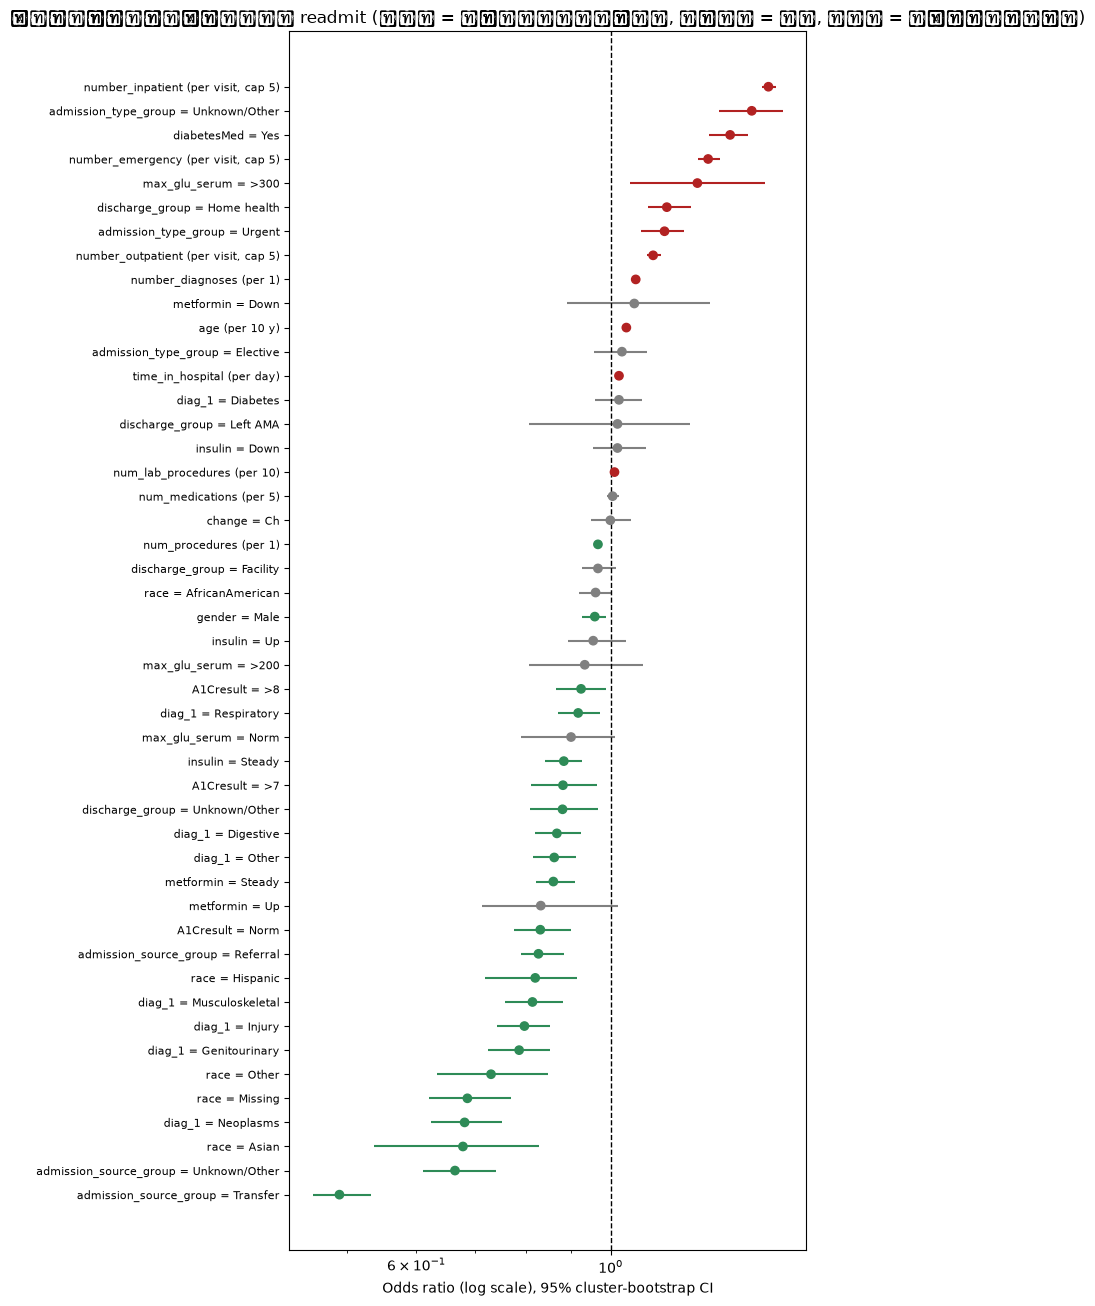

In [8]:
t = or_table.sort_values("OR")
fig, ax = plt.subplots(figsize=(8, max(6, 0.28 * len(t))))
colors = np.where(t["significant"], np.where(t["OR"] > 1, "firebrick", "seagreen"), "grey")
ax.hlines(range(len(t)), t["CI_low"], t["CI_high"], colors=colors, lw=1.5)
ax.scatter(t["OR"], range(len(t)), c=colors, zorder=3)
ax.axvline(1, ls="--", c="k", lw=1)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Odds ratio (log scale), 95% cluster-bootstrap CI")
ax.set_title("ปัจจัยที่สัมพันธ์กับการ readmit (แดง = เพิ่มความเสี่ยง, เขียว = ลด, เทา = ไม่มีนัยสำคัญ)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/B_forest_plot.png", dpi=150); plt.show()

## ชั้น C — โมเดลใช้อะไร: SHAP + Permutation Importance

- **SHAP** คำนวณจาก XGBoost (hyperparameter เดียวกับใน stacking) ที่เทรนบน train แล้วอธิบายบน val ใช้ TreeSHAP ในตัวของ xgboost (`pred_contribs`) ได้ค่าเหมือน shap.TreeExplainer ทุกประการ
- **Permutation importance** คำนวณจาก **stacking ตัวจริง** (`model_11_any.pkl`) บน val — ยืนยันว่าข้อสรุปจาก XGBoost ใช้กับโมเดลหลักได้ด้วย

In [9]:
XGB_PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.01, subsample=0.9,
                  eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

xgb_model = xgb.XGBClassifier(**XGB_PARAMS,
                              scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum())
xgb_model.fit(X_tr, y_tr)
print(f"XGBoost val ROC-AUC: {roc_auc_score(y_va, xgb_model.predict_proba(X_va)[:, 1]):.4f}")

X_shap = X_va.sample(n=min(SHAP_SAMPLE, len(X_va)), random_state=RANDOM_STATE)
booster = xgb_model.get_booster()
shap_values = booster.predict(xgb.DMatrix(X_shap), pred_contribs=True)[:, :-1]  # คอลัมน์สุดท้าย = bias
shap_df = pd.DataFrame(shap_values, columns=X_shap.columns, index=X_shap.index)
mean_abs_shap = shap_df.abs().mean().sort_values(ascending=False)
print("\nMean |SHAP| (top 15):\n", mean_abs_shap.head(15).round(4).to_string())

XGBoost val ROC-AUC: 0.6773

Mean |SHAP| (top 15):
 total_prior_visits           0.2850
hospital_stay_x_inpatient    0.0794
number_diagnoses             0.0794
admission_source_id          0.0627
number_inpatient             0.0623
visit_number                 0.0600
age_x_medications            0.0475
diabetesMed                  0.0381
age_ord                      0.0369
diag_1                       0.0257
num_procedures               0.0223
medical_specialty            0.0196
time_in_hospital             0.0133
number_emergency             0.0109
race                         0.0107


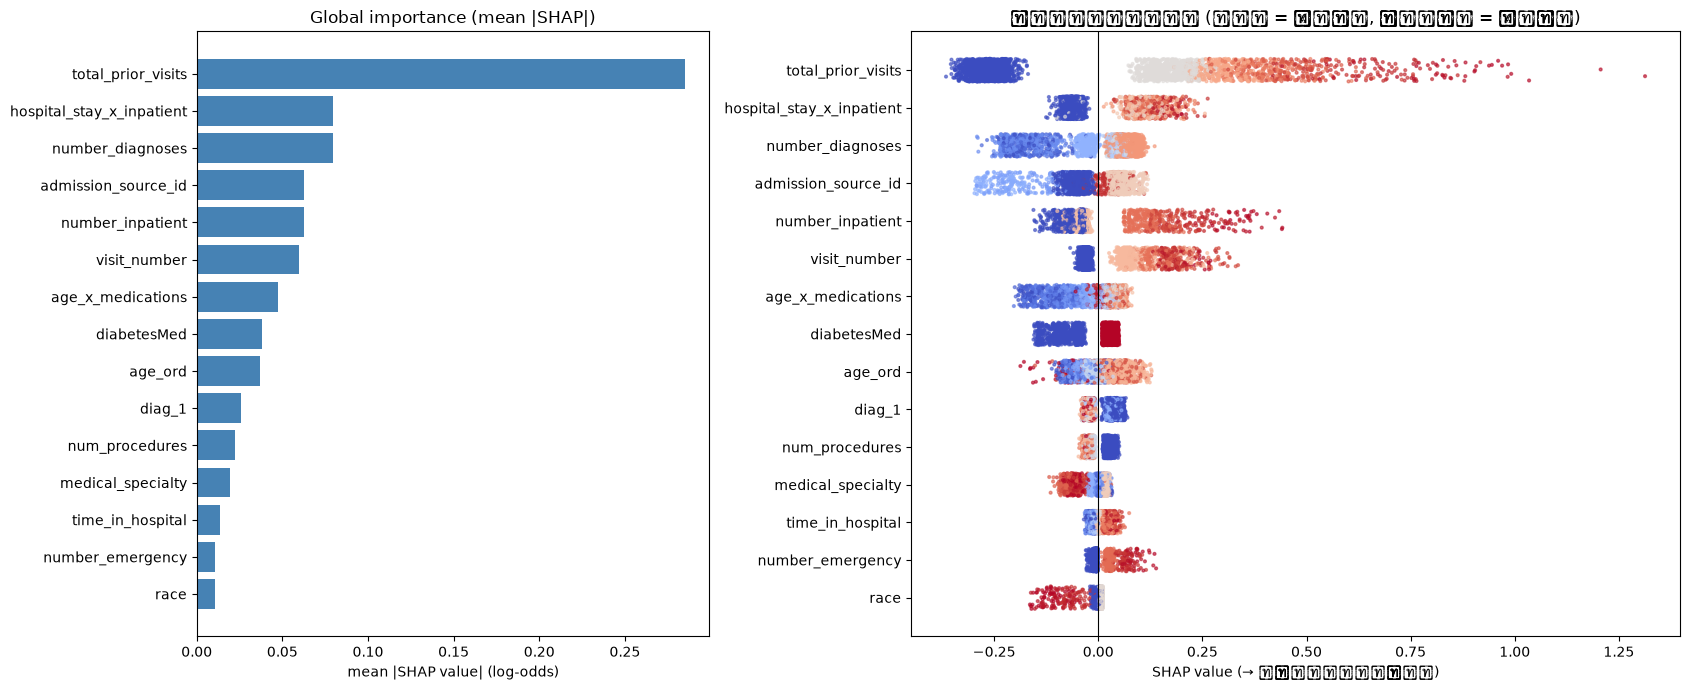

In [10]:
TOP = 15
top_feats = mean_abs_shap.index[:TOP][::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1, 1.5]})
a1.barh(top_feats, mean_abs_shap[top_feats], color="steelblue")
a1.set_title("Global importance (mean |SHAP|)"); a1.set_xlabel("mean |SHAP value| (log-odds)")

# beeswarm แบบง่าย: สี = ค่าของ feature (percentile rank ภายใน feature)
rng_j = np.random.default_rng(0)
for i, f in enumerate(top_feats):
    vals = X_shap[f].rank(pct=True).values
    a2.scatter(shap_df[f], i + rng_j.uniform(-0.3, 0.3, len(vals)), c=vals, cmap="coolwarm", s=4, alpha=0.6)
a2.axvline(0, c="k", lw=0.8)
a2.set_yticks(range(TOP)); a2.set_yticklabels(top_feats)
a2.set_xlabel("SHAP value (→ เพิ่มความเสี่ยง)"); a2.set_title("ทิศทางของผล (แดง = ค่าสูง, น้ำเงิน = ค่าต่ำ)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/C1_shap_summary.png", dpi=150); plt.show()

### C2. Dependence plot — รูปทรงของความสัมพันธ์
ดูว่าความเสี่ยงเพิ่มแบบเส้นตรง, อิ่มตัว (plateau) หรือมี threshold — ข้อมูลนี้ใช้เขียนส่วน "ความเข้าใจโรค" ได้ตรงๆ เช่น "ความเสี่ยงเพิ่มชัดตั้งแต่ admit ครั้งแรก แล้วค่อยๆ อิ่มตัวหลัง 3 ครั้ง"

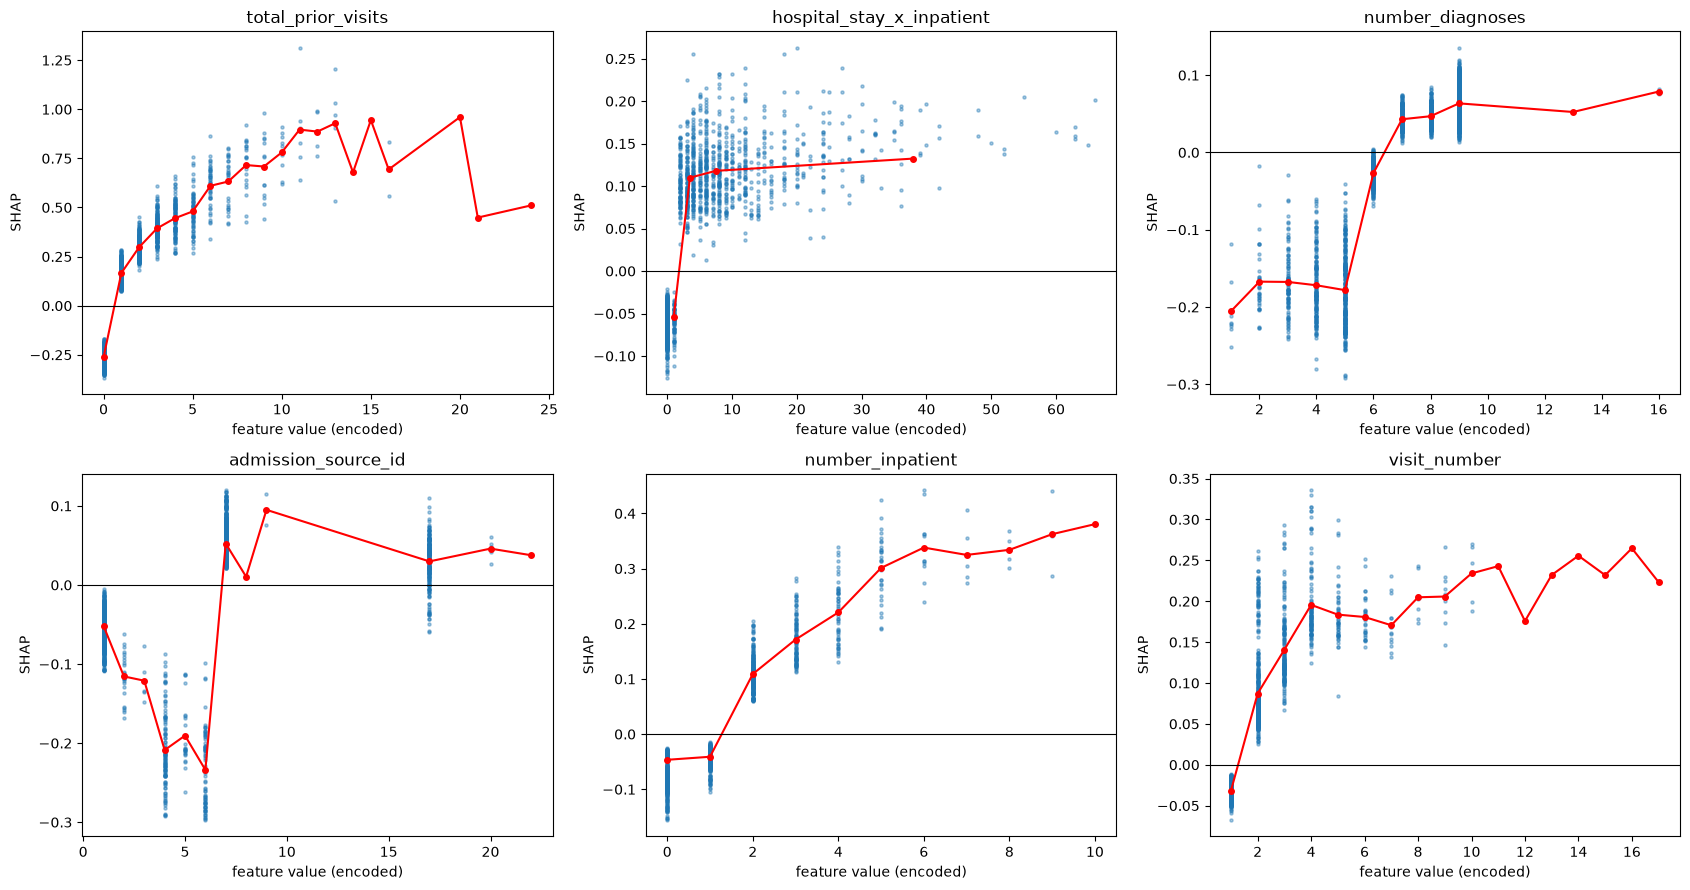

In [11]:
dep_feats = list(mean_abs_shap.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, f in zip(axes.ravel(), dep_feats):
    ax.scatter(X_shap[f], shap_df[f], s=5, alpha=0.4)
    # ค่าเฉลี่ย SHAP ต่อระดับ (หรือต่อ bin ถ้าค่าต่อเนื่อง)
    xs = X_shap[f] if X_shap[f].nunique() <= 20 else pd.qcut(X_shap[f], 10, duplicates="drop").apply(lambda iv: iv.mid)
    m = shap_df[f].groupby(xs).mean()
    ax.plot(m.index.astype(float), m.values, "r-o", ms=4)
    ax.axhline(0, c="k", lw=0.8); ax.set_title(f); ax.set_xlabel("feature value (encoded)"); ax.set_ylabel("SHAP")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/C2_shap_dependence.png", dpi=150); plt.show()

### C3. SHAP Interaction — คู่ตัวแปรที่ส่งผลร่วมกัน
ค่า interaction สูง = ผลของตัวแปร A **ขึ้นกับค่าของ** ตัวแปร B (เช่น การนอนนานอาจเสี่ยงเฉพาะในคนที่เคย admit มาก่อน) คู่ที่เจอตรงนี้จะเป็น candidate feature ในชั้น D

             feature_a                  feature_b  mean_abs_interaction
0     number_inpatient         total_prior_visits               0.05838
1   total_prior_visits  hospital_stay_x_inpatient               0.02829
2  admission_source_id         total_prior_visits               0.02543
3         visit_number         total_prior_visits               0.02501
4   total_prior_visits                    age_ord               0.02369
5     number_diagnoses         total_prior_visits               0.02283
6          diabetesMed         total_prior_visits               0.02218
7  admission_source_id           number_diagnoses               0.02051
8   total_prior_visits          age_x_medications               0.01640
9  admission_source_id          age_x_medications               0.01572


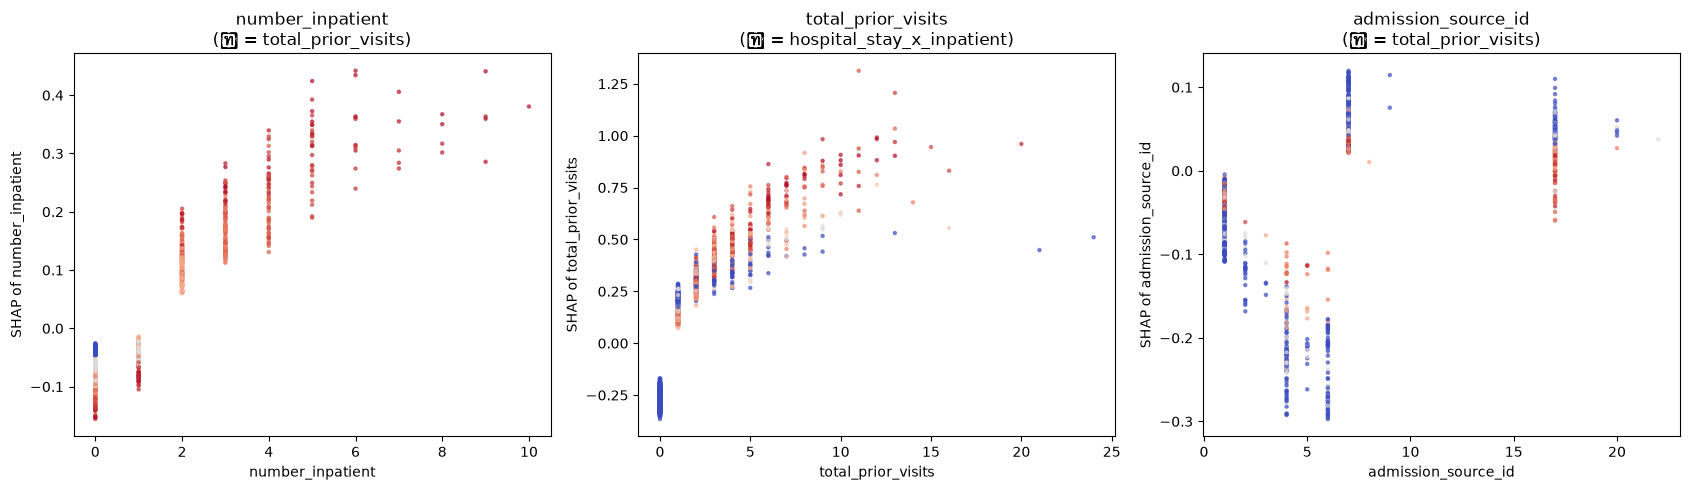

In [12]:
X_int = X_shap.iloc[:INTER_SAMPLE]
inter = booster.predict(xgb.DMatrix(X_int), pred_interactions=True)[:, :-1, :-1]
mean_inter = np.abs(inter).mean(axis=0)
np.fill_diagonal(mean_inter, 0)
feats = X_int.columns
pairs = [(feats[i], feats[j], mean_inter[i, j] * 2)   # *2 เพราะ interaction แบ่งเท่าๆ กันใน (i,j) และ (j,i)
         for i in range(len(feats)) for j in range(i + 1, len(feats))]
inter_df = (pd.DataFrame(pairs, columns=["feature_a", "feature_b", "mean_abs_interaction"])
            .sort_values("mean_abs_interaction", ascending=False).reset_index(drop=True))
inter_df.head(20).to_csv(f"{OUT_DIR}/C3_top_interactions.csv", index=False)
print(inter_df.head(10).round(5).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (_, r) in zip(axes, inter_df.head(3).iterrows()):
    a, b = r["feature_a"], r["feature_b"]
    sc = ax.scatter(X_shap[a], shap_df[a], c=X_shap[b].rank(pct=True), cmap="coolwarm", s=5, alpha=0.6)
    ax.set_title(f"{a}\n(สี = {b})"); ax.set_xlabel(a); ax.set_ylabel(f"SHAP of {a}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/C3_interaction_plots.png", dpi=150); plt.show()

In [13]:
# Permutation importance ของ stacking ตัวจริงจาก notebook 11 (บน val, subsample เพื่อความเร็ว)
bundle = joblib.load(MODEL_PATH)
assert bundle["feature_names"] == list(X_va.columns), "feature ไม่ตรงกับตอนเทรนใน 11"
stack = bundle["stacking_model"]

X_pi = X_va.sample(n=min(5000, len(X_va)), random_state=RANDOM_STATE)
y_pi = y_va.loc[X_pi.index]
pi = permutation_importance(stack, X_pi, y_pi, scoring="roc_auc", n_repeats=3,
                            random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=X_pi.columns).sort_values(ascending=False)
print("Permutation importance ของ stacking (ROC-AUC ที่ลดลงเมื่อสลับค่า feature):")
print(perm.head(15).round(4).to_string())
print("\nหมายเหตุ: feature ที่ซ้ำซ้อนกัน (เช่น number_inpatient กับ had_prior_inpatient) จะได้ค่าต่ำกว่าจริง "
      "เพราะโมเดลยังใช้อีกตัวแทนได้ — ดูประกอบกับ SHAP เสมอ")

Permutation importance ของ stacking (ROC-AUC ที่ลดลงเมื่อสลับค่า feature):
total_prior_visits           0.0568
number_diagnoses             0.0110
number_inpatient             0.0081
visit_number                 0.0060
admission_source_id          0.0059
hospital_stay_x_inpatient    0.0048
age_ord                      0.0043
admission_type_id            0.0040
age_x_medications            0.0038
had_prior_inpatient          0.0036
num_procedures               0.0030
diabetesMed                  0.0029
time_in_hospital             0.0021
number_emergency             0.0020
num_lab_procedures           0.0020

หมายเหตุ: feature ที่ซ้ำซ้อนกัน (เช่น number_inpatient กับ had_prior_inpatient) จะได้ค่าต่ำกว่าจริง เพราะโมเดลยังใช้อีกตัวแทนได้ — ดูประกอบกับ SHAP เสมอ


### C4. ตารางสรุป: แต่ละวิธีเห็นตรงกันไหม
ใช้อันดับ (rank) ของแต่ละวิธี — feature ที่ติดอันดับต้นในทุกวิธีคือข้อค้นพบที่แข็งแรงที่สุด ใช้ตารางนี้ในเปเปอร์ได้เลย

In [14]:
agree = pd.DataFrame({
    "MI_rank": mi.rank(ascending=False),
    "SHAP_rank": mean_abs_shap.rank(ascending=False),
    "Perm_rank": perm.rank(ascending=False),
})
agree["mean_rank"] = agree.mean(axis=1)
agree = agree.sort_values("mean_rank").astype(int)
agree.to_csv(f"{OUT_DIR}/C4_rank_agreement.csv")
print(agree.head(15).to_string())
print(f"\nSpearman correlation ระหว่างอันดับ:\n{agree[['MI_rank','SHAP_rank','Perm_rank']].corr(method='spearman').round(2)}")

                           MI_rank  SHAP_rank  Perm_rank  mean_rank
total_prior_visits               1          1          1          1
number_inpatient                 2          5          3          3
hospital_stay_x_inpatient        3          2          6          3
number_diagnoses                 8          3          2          4
visit_number                     4          6          4          4
admission_source_id              9          4          5          6
age_x_medications               10          7          9          8
number_emergency                 7         14         14         11
age_ord                         23          9          7         13
medical_specialty               12         12         18         14
time_in_hospital                17         13         13         14
admission_type_id               18         18          8         14
diabetesMed                     24          8         12         14
num_lab_procedures              15         16   

## ชั้น D — Feature ใหม่ช่วยเพิ่มผลไหม (controlled test)

**วิธีทดสอบ**: XGBoost (hyperparameter คงที่) + GroupKFold 5 fold บน train เทียบ baseline กับ baseline + feature กลุ่มใหม่ แล้วดู **ผลต่างราย fold (paired)** ถือว่า "ช่วยจริง" ก็ต่อเมื่อดีขึ้น **ทุก fold** และค่าเฉลี่ยมากกว่า 2 เท่าของ SD ของผลต่าง

Candidate มาจากสิ่งที่เจอในชั้น A–C:
- **discharge**: กลุ่มปลายทางหลังจำหน่าย (ปัจจุบันโมเดลเห็นเป็นรหัสตัวเลข ที่เรียงลำดับไม่มีความหมาย)
- **utilization**: รูปแบบการใช้บริการ (ER + inpatient รวมกัน, log, flag)
- **insulin**: การปรับ insulin (ตัวยาหลักของคนที่ควบคุมน้ำตาลไม่ได้)
- **shap_pairs**: ผลคูณของ 3 คู่ที่มี interaction สูงสุดจาก C3 (สร้างอัตโนมัติ)

In [15]:
def add_candidates(Xe, R, pairs):
    """Xe = X แบบ encoded, R = readable ของแถวเดียวกัน, pairs = [(a, b), ...] จาก C3"""
    out = {}
    dg = R["discharge_disposition_id"].apply(group_discharge).values
    out["discharge"] = pd.DataFrame({
        "dc_facility": (dg == "Facility").astype(int),
        "dc_home_health": (dg == "Home health").astype(int),
        "dc_left_ama": (dg == "Left AMA").astype(int),
    }, index=Xe.index)
    out["utilization"] = pd.DataFrame({
        "acute_prior_visits": R["number_inpatient"].values + R["number_emergency"].values,
        "log_total_prior": np.log1p(R["total_prior_visits"].values),
        "any_prior_emergency": (R["number_emergency"].values > 0).astype(int),
        "inpatient_x_emergency": R["number_inpatient"].values * R["number_emergency"].values,
    }, index=Xe.index)
    out["insulin"] = pd.DataFrame({
        "insulin_adjusted": R["insulin"].isin(["Up", "Down"]).astype(int).values,
        "insulin_up": (R["insulin"] == "Up").astype(int).values,
    }, index=Xe.index)
    out["shap_pairs"] = pd.DataFrame({f"{a}__x__{b}": Xe[a].values * Xe[b].values for a, b in pairs},
                                     index=Xe.index)
    return out

top_pairs = [(r.feature_a, r.feature_b) for r in inter_df.head(3).itertuples()]
cand_tr = add_candidates(X_tr, R_tr, top_pairs)
feature_sets = {"baseline": []}
feature_sets.update({k: [k] for k in cand_tr})
feature_sets["all_new"] = list(cand_tr)

def make_model(y_fit):
    if HAS_XGB:
        return xgb.XGBClassifier(**XGB_PARAMS, scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum())
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300,
                                          class_weight="balanced", random_state=RANDOM_STATE)

folds = list(GroupKFold(n_splits=5).split(X_tr, y_tr, groups=g_tr))
records = []
for name, blocks in feature_sets.items():
    Xs = pd.concat([X_tr] + [cand_tr[b] for b in blocks], axis=1)
    for k, (a, b) in enumerate(folds):
        m = make_model(y_tr.iloc[a]).fit(Xs.iloc[a], y_tr.iloc[a])
        p = m.predict_proba(Xs.iloc[b])[:, 1]
        records.append({"set": name, "fold": k, "ROC_AUC": roc_auc_score(y_tr.iloc[b], p),
                        "PR_AUC": average_precision_score(y_tr.iloc[b], p)})
    print(f"  done: {name}")
cv = pd.DataFrame(records)

  done: baseline
  done: discharge
  done: utilization
  done: insulin
  done: shap_pairs
  done: all_new


In [16]:
base_cv = cv[cv["set"] == "baseline"].set_index("fold")
summary = []
for name in feature_sets:
    s = cv[cv["set"] == name].set_index("fold")
    for metric in ["ROC_AUC", "PR_AUC"]:
        d = s[metric] - base_cv[metric]
        summary.append({
            "set": name, "metric": metric,
            "mean": round(s[metric].mean(), 4),
            "delta_vs_baseline": round(d.mean(), 4),
            "delta_sd": round(d.std(), 4),
            "folds_improved": f"{(d > 0).sum()}/5",
            "verdict": ("—" if name == "baseline" else
                        "ช่วยจริง" if (d > 0).all() and d.mean() > 2 * d.std() else "อยู่ในช่วง noise"),
        })
summary = pd.DataFrame(summary)
summary.to_csv(f"{OUT_DIR}/D_feature_test.csv", index=False)
print(summary.to_string(index=False))

        set  metric   mean  delta_vs_baseline  delta_sd folds_improved          verdict
   baseline ROC_AUC 0.6790             0.0000    0.0000            0/5                —
   baseline  PR_AUC 0.6546             0.0000    0.0000            0/5                —
  discharge ROC_AUC 0.6794             0.0004    0.0003            5/5 อยู่ในช่วง noise
  discharge  PR_AUC 0.6554             0.0008    0.0008            4/5 อยู่ในช่วง noise
utilization ROC_AUC 0.6793             0.0002    0.0006            3/5 อยู่ในช่วง noise
utilization  PR_AUC 0.6547             0.0001    0.0009            2/5 อยู่ในช่วง noise
    insulin ROC_AUC 0.6790            -0.0000    0.0001            2/5 อยู่ในช่วง noise
    insulin  PR_AUC 0.6546             0.0000    0.0001            3/5 อยู่ในช่วง noise
 shap_pairs ROC_AUC 0.6787            -0.0003    0.0006            1/5 อยู่ในช่วง noise
 shap_pairs  PR_AUC 0.6543            -0.0003    0.0008            1/5 อยู่ในช่วง noise
    all_new ROC_AUC 0.6793      

## สรุปและบันทึกผล

**วิธีใช้ผลในเปเปอร์**
- ส่วน *Results — Risk factors*: forest plot (B) + ตาราง OR ของตัวที่มีนัยสำคัญ + ตารางความสอดคล้อง (C4)
- ส่วน *Discussion — understanding diabetes readmission*: รูปทรงความสัมพันธ์จาก dependence plot (C2) และคู่ interaction (C3)
- ส่วน *Feature engineering*: ตาราง D — ถ้าไม่มีกลุ่มไหน "ช่วยจริง" ให้เขียนเป็น negative finding ที่ยืนยัน data ceiling ร่วมกับผลของ notebook 08
- เทียบ val ROC-AUC ของ logistic regression กับ stacking: ถ้าใกล้กัน แปลว่าโมเดลเรียบง่ายที่ตีความได้ก็พอ ซึ่งเป็นข้อค้นพบที่มีประโยชน์ในทางคลินิก

**Feature กลุ่มที่ผ่านเกณฑ์ "ช่วยจริง"** จะถูกนำไปใช้ใน notebook 13 (survival) และ 14 (LSTM) เพื่อให้ทุกโมเดลใช้ข้อมูลชุดเดียวกัน

In [17]:
adopted = sorted(set(summary.loc[(summary["verdict"] == "ช่วยจริง") & (summary["metric"] == "ROC_AUC"), "set"]) - {"all_new"})
with open(f"{OUT_DIR}/adopted_feature_blocks.json", "w") as f:
    json.dump({"label_mode": LABEL_MODE, "adopted_blocks": adopted, "shap_pairs": top_pairs}, f, indent=2, ensure_ascii=False)
print(f"Feature กลุ่มที่นำไปใช้ต่อ: {adopted if adopted else 'ไม่มี (ใช้ feature set เดิม)'}")
print(f"บันทึกผลทั้งหมดไว้ที่ {OUT_DIR}/")

Feature กลุ่มที่นำไปใช้ต่อ: ไม่มี (ใช้ feature set เดิม)
บันทึกผลทั้งหมดไว้ที่ ../outputs/12_features_any/
